In [27]:
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

DATA_PATH = r'd:\Desktop\Michael\Electric Grid Outage.csv'
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join(os.getcwd(), 'Electric Grid Outage.csv')
print('Dataset path:', DATA_PATH)
print('File exists:', os.path.exists(DATA_PATH))


Dataset path: d:\Desktop\Michael\Electric Grid Outage.csv
File exists: True


In [28]:
df = pd.read_csv(DATA_PATH)
print(df.head().to_string(index=False))
print('\nShape:', df.shape)
print('\nColumns:', list(df.columns))
print('\nNull values:\n', df.isna().sum())

df['Date Event Began'] = pd.to_datetime(df['Date Event Began'], errors='coerce')
df['Demand Loss (MW)'] = pd.to_numeric(df['Demand Loss (MW)'], errors='coerce')
df['Number of Customers Affected'] = pd.to_numeric(df['Number of Customers Affected'], errors='coerce')
df['Event Month'] = df['Event Month'].astype(str).str.strip()
df['Area Affected'] = df['Area Affected'].fillna('Unknown').astype(str).str.strip()

def normalize_region(value):
    if pd.isna(value):
        return 'Unknown'
    cleaned = str(value).strip().replace(' / ', '/').replace(' ', '').upper()
    if 'WECC' in cleaned:
        return 'WECC'
    if 'SERC' in cleaned:
        return 'SERC'
    if 'MRO' in cleaned:
        return 'MRO'
    if 'NPCC' in cleaned:
        return 'NPCC'
    if 'TRE' in cleaned:
        return 'TRE'
    if 'RF' in cleaned:
        return 'RF'
    return 'Unknown'

df['NERC Region'] = df['NERC Region'].map(normalize_region)
print('\nNormalized region counts:\n', df['NERC Region'].value_counts())


 Event Year Event Month Date Event Began                  Area Affected NERC Region Demand Loss (MW) Number of Customers Affected
       2023     January       01/01/2023  California: Riverside County;        WECC                0                            0
       2023     January       01/01/2023 California: Sacramento County;        WECC                0                            0
       2023     January       01/01/2023        Florida: Citrus County;        SERC               19                         3509
       2023     January       01/02/2023          Texas: Dallas County;         TRE                0                            0
       2023     January       01/02/2023                    New Mexico:        WECC              432                            0

Shape: (167, 7)

Columns: ['Event Year', 'Event Month', 'Date Event Began', 'Area Affected', 'NERC Region', 'Demand Loss (MW)', 'Number of Customers Affected']

Null values:
 Event Year                      0
Event Mont

                              count unique                             top  \
Event Year                    167.0    NaN                             NaN   
Event Month                     167      6                           March   
Date Event Began                167    NaN                             NaN   
Area Affected                   167    132  California: Sacramento County;   
NERC Region                     167      6                            SERC   
Demand Loss (MW)              126.0    NaN                             NaN   
Number of Customers Affected  148.0    NaN                             NaN   

                             freq                        mean  \
Event Year                    NaN                      2023.0   
Event Month                    46                         NaN   
Date Event Began              NaN  2023-03-18 02:00:43.113772   
Area Affected                   5                         NaN   
NERC Region                    47                 

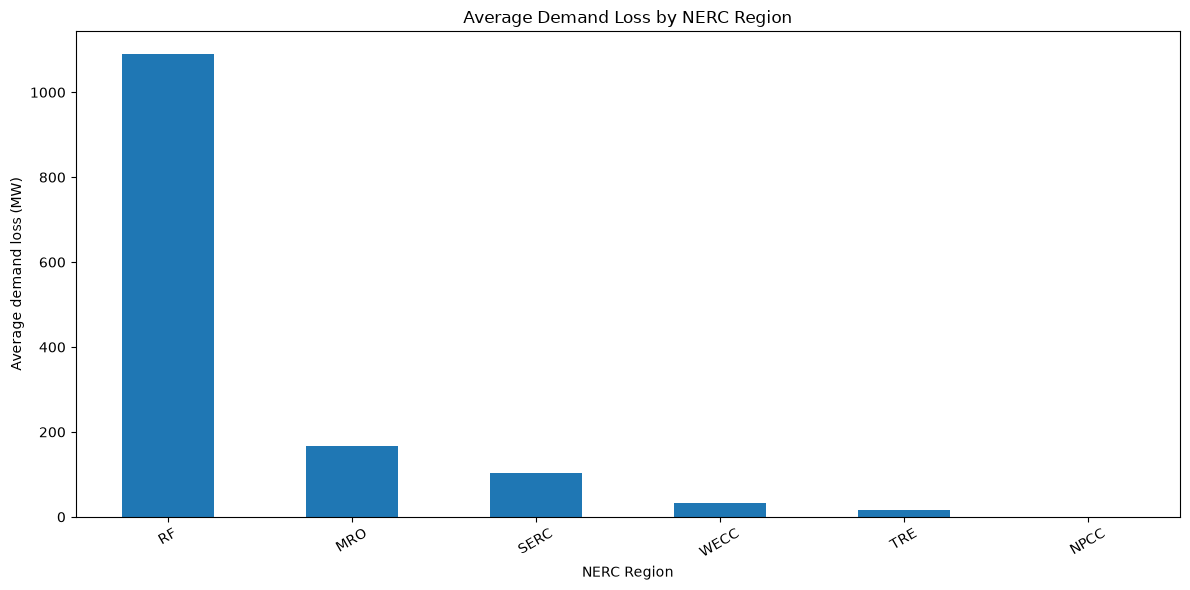

In [29]:
print(df.describe(include='all').T)
print('\nAverage demand loss by NERC region:\n')
print(df.groupby('NERC Region')['Demand Loss (MW)'].mean().round(2).sort_values(ascending=False))

avg_demand = df.groupby('NERC Region')['Demand Loss (MW)'].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
avg_demand.plot(kind='bar')
plt.title('Average Demand Loss by NERC Region')
plt.ylabel('Average demand loss (MW)')
plt.xlabel('NERC Region')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


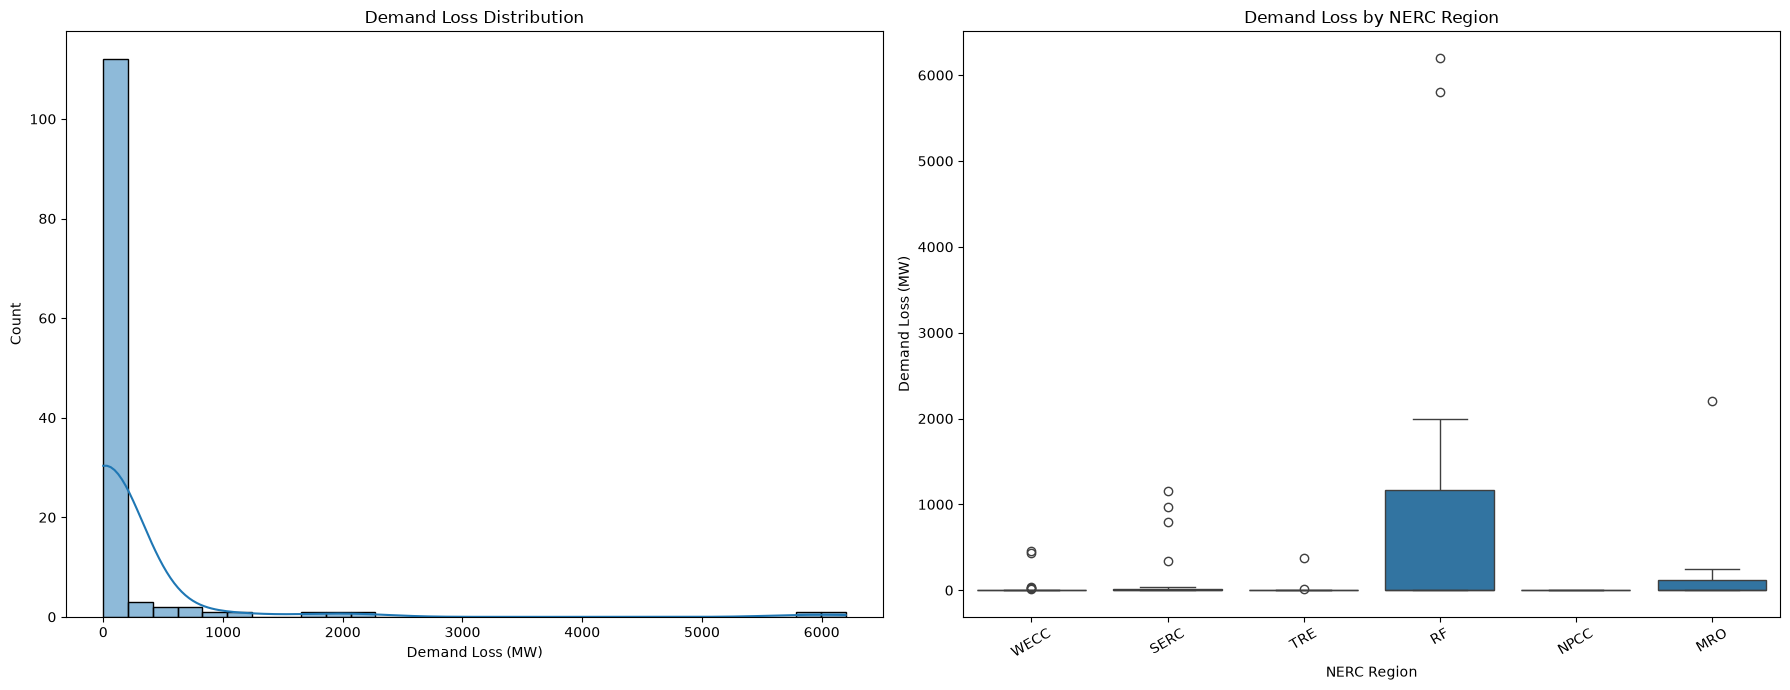

NERC Region
SERC    47
WECC    36
TRE     31
RF      24
MRO     20
NPCC     9
Name: count, dtype: int64


In [30]:
plt.figure(figsize=(18, 7))
plt.subplot(1, 2, 1)
sns.histplot(df['Demand Loss (MW)'], kde=True, bins=30)
plt.title('Demand Loss Distribution')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='NERC Region', y='Demand Loss (MW)')
plt.title('Demand Loss by NERC Region')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(df['NERC Region'].value_counts())


In [31]:
feature_columns = [
    'Event Year', 'Event Month', 'Area Affected',
    'Demand Loss (MW)', 'Number of Customers Affected'
]
X = df[feature_columns].copy()
y = df['NERC Region']

print('Features:', feature_columns)
print('Target classes:\n', y.value_counts())


Features: ['Event Year', 'Event Month', 'Area Affected', 'Demand Loss (MW)', 'Number of Customers Affected']
Target classes:
 NERC Region
SERC    47
WECC    36
TRE     31
RF      24
MRO     20
NPCC     9
Name: count, dtype: int64


5-fold CV accuracy: 0.875 +/- 0.044
5-fold CV macro F1: 0.875 +/- 0.050

Out-of-fold classification report:
              precision    recall  f1-score   support

         MRO       0.94      0.75      0.83        20
        NPCC       1.00      0.89      0.94         9
          RF       0.78      0.88      0.82        24
        SERC       0.87      0.87      0.87        47
         TRE       0.81      0.94      0.87        31
        WECC       0.97      0.89      0.93        36

    accuracy                           0.87       167
   macro avg       0.89      0.87      0.88       167
weighted avg       0.88      0.87      0.88       167



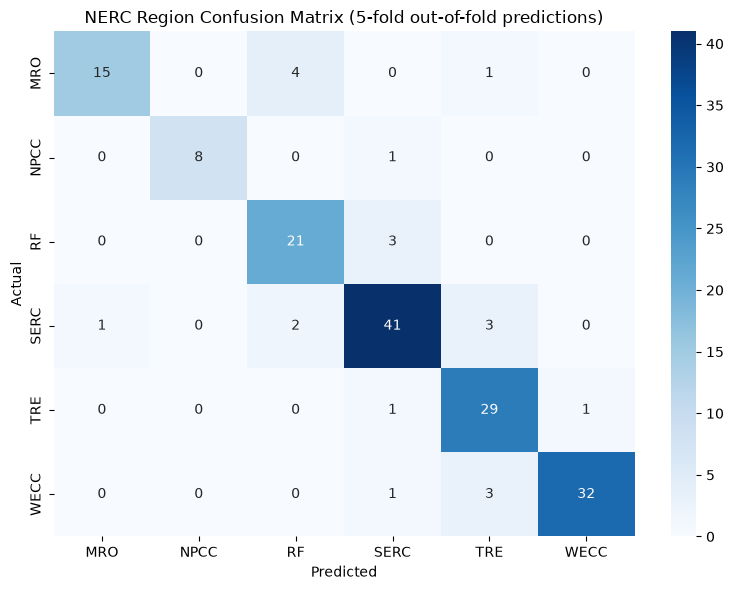

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](6,)","['MRO','NPCC','RF','SERC','TRE','WECC']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Event Year','Event Month','Area Affected','Demand Loss (MW)', 'Number of Customers Affected']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('month', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (d

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import LinearSVC

numeric_features = ['Event Year', 'Demand Loss (MW)', 'Number of Customers Affected']
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), numeric_features),
        ('month', OneHotEncoder(handle_unknown='ignore'), ['Event Month']),
        ('area', TfidfVectorizer(ngram_range=(1, 2), strip_accents='unicode'), 'Area Affected'),
    ]
)

model = Pipeline([
    ('features', preprocessor),
    ('classifier', LinearSVC(C=0.5, class_weight='balanced', random_state=42)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_validate(
    model, X, y, cv=cv,
    scoring={'accuracy': 'accuracy', 'macro_f1': 'f1_macro'},
)
print(f"5-fold CV accuracy: {cv_scores['test_accuracy'].mean():.3f} "
      f"+/- {cv_scores['test_accuracy'].std():.3f}")
print(f"5-fold CV macro F1: {cv_scores['test_macro_f1'].mean():.3f} "
      f"+/- {cv_scores['test_macro_f1'].std():.3f}")

y_pred = cross_val_predict(model, X, y, cv=cv)
print('\nOut-of-fold classification report:')
print(classification_report(y, y_pred, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('NERC Region Confusion Matrix (5-fold out-of-fold predictions)')
plt.tight_layout()
plt.show()

model.fit(X, y)
